# Simulating Airway Mechanics


## 2D Node-Spring Network

We model the transverse cross-section of the airway wall as a two-dimensional node-spring network arranged in an annular topology. The network consists of discrete point masses (nodes) connected by elastic springs, with each node representing a localized volume element of airway tissue (such as a cellular cluster or a region of extracellular matrix (ECM)), while springs encode the effective mechanical interactions between neighboring tissue elements. 

The system is organized into concentric radial layers, each subdivided into uniform angular segments, forming a structured lattice that corresponds directly to the layered histological architecture of the airway. This annular topology naturally accommodates the dominant deformation modes including radial thickening and circumferential shortening that characterize airway constriction under physiological and pathological loading. Further, by assigning layer-specific elastic parameters to different radial regions, the framework accommodates physiologically relevant heterogeneity and enables simulation of disease-related remodeling, such as airway smooth muscle hypercontractility or extracellular matrix stiffening in chronic asthma.

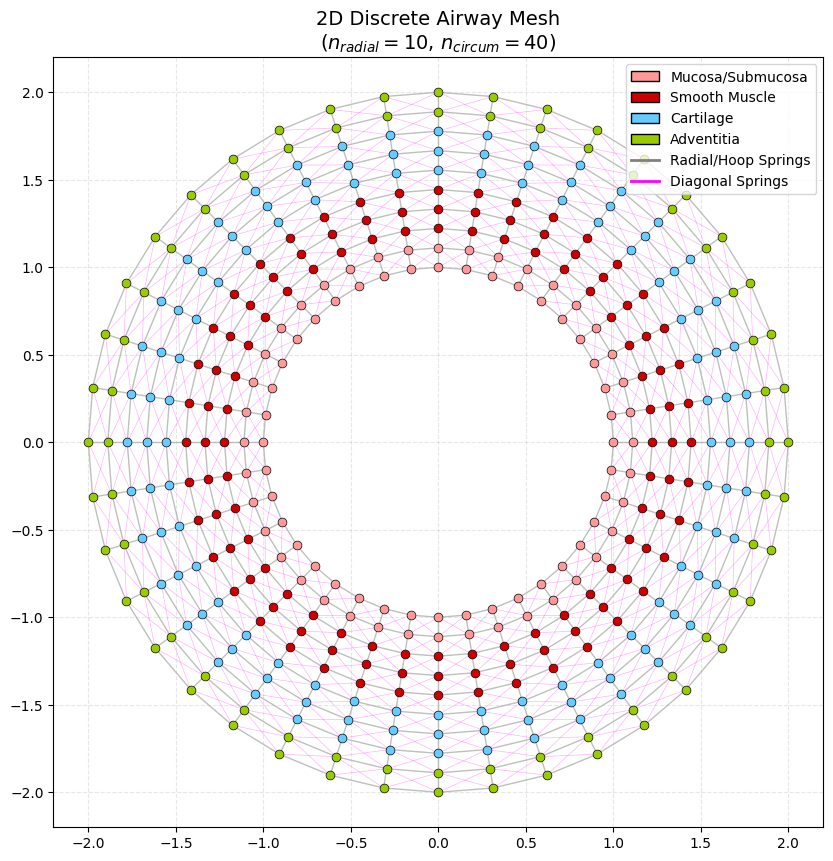

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

class AirwayMesh:
    def __init__(self, r_inner, r_outer, n_radial, n_circum):
        self.r_inner = r_inner
        self.r_outer = r_outer
        self.n_radial = n_radial
        self.n_circum = n_circum
        
        # Store node coordinates (r_index, c_index) -> (x, y)
        self.nodes = np.zeros((n_radial, n_circum, 2))
        
        # Define Tissue Layers (Proportional mapping for visualization)
        # We assign specific radial indices to tissues
        self.layer_map = []
        for r in range(n_radial):
            ratio = r / (n_radial - 1)
            if ratio < 0.2:
                self.layer_map.append(('Mucosa/Submucosa', '#FF9999')) # Pink
            elif ratio < 0.5:
                self.layer_map.append(('Smooth Muscle', '#CC0000'))   # Red
            elif ratio < 0.8:
                self.layer_map.append(('Cartilage', '#66CCFF'))       # Blue
            else:
                self.layer_map.append(('Adventitia', '#99CC00'))      # Green

    def generate_mesh(self):
        """
        Generates the mesh based on the Polar -> Cartesian logic
        described in your paper.
        """
        for r in range(self.n_radial):
            # 1. Linear Interpolation for Radius (The formula from your paper)
            radius = self.r_inner + (self.r_outer - self.r_inner) * (r / (self.n_radial - 1))
            
            for c in range(self.n_circum):
                # 2. Angular Sector division
                theta = (2 * np.pi * c) / self.n_circum
                
                # 3. Polar to Cartesian Conversion
                x = radius * np.cos(theta)
                y = radius * np.sin(theta)
                
                self.nodes[r, c] = [x, y]

    def plot(self, show_diagonal=True):
        fig, ax = plt.subplots(figsize=(10, 10))
        ax.set_aspect('equal')
        ax.set_title(f"2D Discrete Airway Mesh\n($n_{{radial}}={self.n_radial}$, $n_{{circum}}={self.n_circum}$)", fontsize=14)
        
        # --- PLOT SPRINGS ---
        # We plot springs first so they appear behind the nodes
        
        # 1. Circumferential Springs (Hoop)
        for r in range(self.n_radial):
            x_vals = []
            y_vals = []
            for c in range(self.n_circum + 1): # +1 to wrap around
                c_idx = c % self.n_circum
                x_vals.append(self.nodes[r, c_idx, 0])
                y_vals.append(self.nodes[r, c_idx, 1])
            ax.plot(x_vals, y_vals, c='gray', alpha=0.5, linewidth=1, zorder=1)

        # 2. Radial Springs
        for c in range(self.n_circum):
            x_vals = self.nodes[:, c, 0]
            y_vals = self.nodes[:, c, 1]
            ax.plot(x_vals, y_vals, c='gray', alpha=0.5, linewidth=1, zorder=1)

        # 3. Diagonal Springs (Shear resistance)
        if show_diagonal:
            for r in range(self.n_radial - 1):
                for c in range(self.n_circum):
                    c_next = (c + 1) % self.n_circum
                    
                    # Node A (Current) -> Node B (Outer, Next)
                    p1 = self.nodes[r, c]
                    p2 = self.nodes[r+1, c_next]
                    
                    # Node C (Current, Next) -> Node D (Outer)
                    p3 = self.nodes[r, c_next]
                    p4 = self.nodes[r+1, c]
                    
                    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], c='magenta', alpha=0.3, linewidth=0.5, zorder=0)
                    ax.plot([p3[0], p4[0]], [p3[1], p4[1]], c='magenta', alpha=0.3, linewidth=0.5, zorder=0)

        # --- PLOT NODES ---
        # Plot nodes layer by layer to assign colors
        unique_labels = {}
        for r in range(self.n_radial):
            label_name, color_code = self.layer_map[r]
            
            # Scatter plot for this ring
            ax.scatter(self.nodes[r, :, 0], self.nodes[r, :, 1], 
                       c=color_code, s=40, zorder=2, edgecolors='black', linewidth=0.5)
            
            # Save for legend
            if label_name not in unique_labels:
                unique_labels[label_name] = color_code

        # --- LEGEND & FORMATTING ---
        legend_elements = [Patch(facecolor=color, edgecolor='black', label=name) 
                           for name, color in unique_labels.items()]
        # Add Spring info to legend
        legend_elements.append(plt.Line2D([0], [0], color='gray', lw=2, label='Radial/Hoop Springs'))
        if show_diagonal:
            legend_elements.append(plt.Line2D([0], [0], color='magenta', lw=2, label='Diagonal Springs'))

        ax.legend(handles=legend_elements, loc='upper right')
        ax.set_xlabel("")
        ax.set_ylabel("")
        plt.grid(True, linestyle='--', alpha=0.3)
        plt.save("airway_mesh.pdf", bbox_inches="tight")
        plt.show()

# Parameters mimicking a bronchiole 
# Inner radius 1.0mm, Outer radius 2.0mm
# 10 layers deep, 40 segments around
mesh = AirwayMesh(r_inner=1.0, r_outer=2.0, n_radial=10, n_circum=40)
mesh.generate_mesh()
mesh.plot(show_diagonal=True)



##### Polar to Cartesian Mapping

The model uses a polar coordinate system to align the discretization with the airway's annular geometry. However, during simulation, all force and displacement calculations are performed using Cartesian coordinates to avoid singularities at the lumen and to simplify numerical analysis.

Each node is indexed by a radial layer $ r \in [0, n_{\text{radial}} - 1] $ and a circumferential sector $ c \in [0, n_{\text{circum}} - 1] $.

The radial position of the $ r^{\text{th}} $ layer is determined by interpolation between the inner and outer airway boundaries. For uniform spacing, this is calculated as
$$
\text{radius} = r_{\text{inner}} + \left( r_{\text{outer}} - r_{\text{inner}} \right) \frac{r}{n_{\text{radial}} - 1}
$$
though extension to non-uniform radial spacing (e.g., via cumulative thickness fractions) is straightforward.

The circumferential position is obtained by dividing the full $ 2\pi $ rotation into $ n_{\text{circum}} $ equal angular sectors,
$$
\theta = \frac{2\pi c}{n_{\text{circum}}}
$$
The Cartesian position of each node is then computed through the standard polar-to-Cartesian transformation:
$$
x = x_{\text{center}} + \text{radius} \cos(\theta), \qquad y = y_{\text{center}} + \text{radius} \sin(\theta),
$$
embedding the anatomically aligned polar lattice into Euclidean space.



### Spring Connectivity 

The mechanical behavior of the network is determined by the connectivity pattern of springs linking adjacent nodes. We employ three classes of springs to form a mechanically complete representation of the airway wall.

1. <u>**Circumferential springs**</u> connect adjacent nodes within the same radial layer, serving as computational analogues of ring-oriented fibers such as collagen, elastin, and smooth muscle bundles. These springs govern the tissue's response to hoop stress arising from luminal pressure or active smooth muscle contraction. Each node is connected to its two circumferential neighbors (at $ c \pm 1 $), forming closed rings that naturally represent the continuity of fiber bundles around the airway perimeter.

2. <u>**Radial springs**</u> link nodes between adjacent rings, providing vertical cohesion across the distinct anatomical layers of the airway wall. Biologically, they correspond to stromal fibers, matrix bridges, and cell–cell or cell–matrix attachments that connect the mucosa, submucosa, and adventitia. These springs prevent the layers from sliding or delaminating under load and help enforce the coordinated, multilayer wall mechanics that characterize intact airways, where deformation in one layer necessarily influences the behavior of adjacent layers. Each node (except those at the innermost and outermost boundaries) is connected to its radial neighbors at layers $ r \pm 1 $.

3. <u>**Diagonal springs**</u> connect nodes offset in both radial and circumferential directions, enabling the mesh to resist shear deformation. They act as equivalents to oblique ECM fibers and cross-linking structures that do not align with the principal anatomical axes. The mesh regions bounded by four springs can undergo a numerical instability called "hourglassing" where nodes deform from rectangles into rhomboid shapes without stretching any springs. This nonphysical behaviour can be eliminated with diagonal springs which ensure that any shear deformation necessarily stretches or compresses springs.






### Force Dynamics

To transform the geometric airway mesh into a mechanically meaningful system, we model tissue interactions through force-based spring mechanics acting on each node in the network. Each spring is assigned a rest length determined by the initial mesh geometry and a stiffness parameter that encodes the effective elastic response of the corresponding tissue elements.

At this stage, all springs are modeled using linear Hookean force laws. For a spring connecting nodes $i$ and $j$, with current length $L_{ij}$ and rest length $L_{ij}^0$, the force magnitude is given by:
$$
F_{ij} = k_{ij} (L_{ij} - L_{ij}^0),
$$
and acts along the unit vector connecting the two nodes. Forces are applied symmetrically and oppositely to the connected nodes, ensuring local force balance and conservation of momentum within the network.

The system is evolved using an overdamped quasi-static formulation appropriate for soft biological tissues, where inertial effects are negligible relative to viscous resistance. Node positions are updated according to:
$$
\mathbf{x}_i^{(t+1)} = \mathbf{x}_i^{(t)} + \Delta t , \frac{\mathbf{F}_i}{\gamma},
$$
where $\mathbf{F}_i$ is the net force acting on node $i$, $\gamma$ is a damping coefficient, and $\Delta t$ is a numerical time step. This formulation allows the mesh to relax toward mechanical equilibrium under applied forces while maintaining numerical stability.

At this stage, all springs are passive and isotropic, and no active contractile forces, nonlinear elasticity, or viscoelastic effects are introduced. This deliberate simplification allows the intrinsic mechanical behavior of the mesh architecture and connectivity to be validated independently of biological complexity. Subsequent model extensions may incorporate layer-specific stiffnesses, active smooth muscle contraction, external pressure loading, and time-dependent material behavior within this same force-based framework.



##
Before adding biology, you should run three sanity experiments:

Zero-force test
Mesh should remain perfectly stable.

Uniform radial expansion
Apply identical outward force → circular symmetry preserved.

Shear perturbation
Displace one ring tangentially → diagonal springs prevent collapse.
